#### Support Vector Machines (SVM)

Import  Needed Packages

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import os

In [10]:
# Set working directory 
path = r'E:\Brain Cancer\GSE_124814\Py-Machine'
os.chdir(path)
print(os.listdir())

# Load data
data = pd.read_csv("Pro_Data.csv")

print(data.head(5))
print(data.shape)

['01-Python-MachineLearning.ipynb', '02-SimpleLinearRegression.ipynb', '03-K-MeansClustering.ipynb', 'GSE124814_HW_expr_matrix.tsv', 'GSE124814_sample_descriptions.xlsx', 'Pro_Data.csv']


C:\Users\Asus\AppData\Local\Temp\ipykernel_16932\970915885.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("Pro_Data.csv")


    Samples      source name gender brain region      A1CF       A2M  \
0  Sample_1  Medulloblastoma      F   cerebellum -0.019300  0.289494   
1  Sample_2  Medulloblastoma      M   cerebellum  0.059848  0.230734   
2  Sample_3  Medulloblastoma      F   cerebellum -0.092846 -0.089454   
3  Sample_4  Medulloblastoma      M   cerebellum -0.097767  0.314725   
4  Sample_5  Medulloblastoma      M   cerebellum  0.118738  1.391229   

      A2ML1    A4GALT     A4GNT      AAAS  ...    ZSWIM6    ZSWIM8      ZW10  \
0  0.213732 -0.402028  0.030517 -0.112330  ... -0.367363  0.551670  0.184700   
1  0.040908 -0.381666 -0.145988  0.092463  ... -1.109660  0.286734 -0.076648   
2 -0.086623 -0.586763 -0.245097 -0.015891  ...  0.427460  0.234605 -0.115306   
3 -0.094998 -0.784063 -0.297410  0.557690  ... -0.266578 -0.898953  0.511287   
4  0.038038 -0.242232 -0.050874  0.067459  ... -0.718445  0.300914  0.471590   

     ZWILCH     ZWINT      ZXDC    ZYG11A    ZYG11B       ZYX      ZZZ3  
0  0.754473 

#### Understanding Data

* samples: include number of samples derived frome pationts and normal cases
* source name: Medulloblastoma(cancer type) and normal
* gender: M(male) and F(female)
* brain region: the area of the brain where the cancer has develope 

#### Pre-processing

In [20]:
Genes = data.iloc[ : , 4: ]
Genes.head(5)

,A1CF,A2M,A2ML1,A4GALT,A4GNT,AAAS,AACS,AADAC,AADACL2,AADAT,...,ZSWIM6,ZSWIM8,ZW10,ZWILCH,ZWINT,ZXDC,ZYG11A,ZYG11B,ZYX,ZZZ3
0,-0.019300,0.289494,0.213732,-0.402028,0.030517,-0.112330,0.327182,0.243028,-0.379652,-0.779346,...,-0.367363,0.551670,0.184700,0.754473,-0.130259,0.170434,0.043495,0.089644,-0.482902,-0.221186
1,0.059848,0.230734,0.040908,-0.381666,-0.145988,0.092463,1.071961,0.072346,-0.196808,0.020437,...,-1.109660,0.286734,-0.076648,1.833178,0.361207,-0.197682,-0.004007,-0.652674,0.204452,-0.492102
2,-0.092846,-0.089454,-0.086623,-0.586763,-0.245097,-0.015891,0.164045,-0.078648,-0.020103,0.239080,...,0.427460,0.234605,-0.115306,1.456536,0.120229,-0.086808,0.114014,0.892811,-0.391065,-0.287110
3,-0.097767,0.314725,-0.094998,-0.784063,-0.297410,0.557690,1.297581,0.213874,0.050398,0.998270,...,-0.266578,-0.898953,0.511287,0.681847,0.551090,-0.275844,-0.042835,-0.635228,-0.248843,-0.396709
4,0.118738,1.391229,0.038038,-0.242232,-0.050874,0.067459,0.037079,0.061993,-0.114732,-0.777357,...,-0.718445,0.300914,0.471590,-0.227464,-0.333867,-0.148096,-0.389286,0.963603,0.060100,-0.097176


In [21]:
Type = data.loc[: , "source name"]
Type.head

<bound method NDFrame.head of 0       Medulloblastoma
1       Medulloblastoma
2       Medulloblastoma
3       Medulloblastoma
4       Medulloblastoma
             ...       
1440    Medulloblastoma
1441    Medulloblastoma
1442    Medulloblastoma
1443    Medulloblastoma
1444    Medulloblastoma
Name: source name, Length: 1445, dtype: object>

In [22]:
# Scale data
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
DataScaled = scale.fit_transform(Genes)
DataScaled

array([[-0.11669552,  0.46448091,  0.99185374, ...,  0.20577891,
        -1.38304335, -0.66235996],
       [ 0.34921149,  0.36708871,  0.18077324, ..., -1.41827847,
         0.57367473, -1.45959303],
       [-0.54962994, -0.16361084, -0.41774858, ...,  1.96296565,
        -1.12160722, -0.85635659],
       ...,
       [ 0.18592664,  2.25075207, -0.03325178, ..., -0.04932583,
         0.19817656, -1.36763636],
       [ 0.69684682, -0.75035937, -0.711654  , ...,  0.58429103,
        -0.00798936, -0.89445443],
       [-0.55245471, -0.30751469,  0.65244857, ...,  0.44659201,
        -0.55281931, -1.0670762 ]])

In [26]:
# PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
pca_data = pca.fit_transform(DataScaled)
print(f'Number of components for %95 variance: {pca.n_components_}')

Number of components for %95 variance: 958


In [31]:
pca_df = pd.DataFrame(
    pca_data,
    columns=[f'PC{i+1}' for i in range (958)],
    index = data.index
)
pca_df["Condition"] = data["source name"].values
pca_df.head(5)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC950,PC951,PC952,PC953,PC954,PC955,PC956,PC957,PC958,Condition
0,-27.831995,-12.886396,11.182982,-25.563751,-11.381456,-35.825399,9.703528,-31.106345,21.565735,-5.691229,...,0.778452,-0.529768,-0.672405,-0.006661,0.689623,-0.892554,-1.024439,-0.922127,0.115467,Medulloblastoma
1,-9.153930,-46.847737,11.423000,-16.559790,-4.273265,6.623035,17.814356,-8.906300,11.804700,-33.559637,...,-1.595961,0.808099,-1.397393,0.800869,-0.679461,2.356125,-0.687595,1.781022,-0.710002,Medulloblastoma
2,-32.994641,-34.882556,21.841162,-10.795092,-5.000645,5.758915,-4.575050,-13.877590,27.202640,-21.760879,...,-1.727417,-1.445199,-1.105243,-0.848353,-0.559734,1.178180,1.551213,1.602874,0.297222,Medulloblastoma
3,50.210640,-81.000433,11.963858,12.258554,-59.597164,-27.001522,15.183117,-19.655196,-6.040972,-38.962473,...,-0.687825,-0.773174,0.309767,0.153451,-0.039170,0.399373,0.981390,-1.075302,-0.070811,Medulloblastoma
4,-28.757478,6.657619,1.951443,-25.892891,-7.296270,-32.274364,29.150762,-37.485257,15.883896,-10.377281,...,0.132741,-0.427298,-1.275723,-0.523458,0.334500,0.450330,-0.379330,1.993158,-0.642730,Medulloblastoma


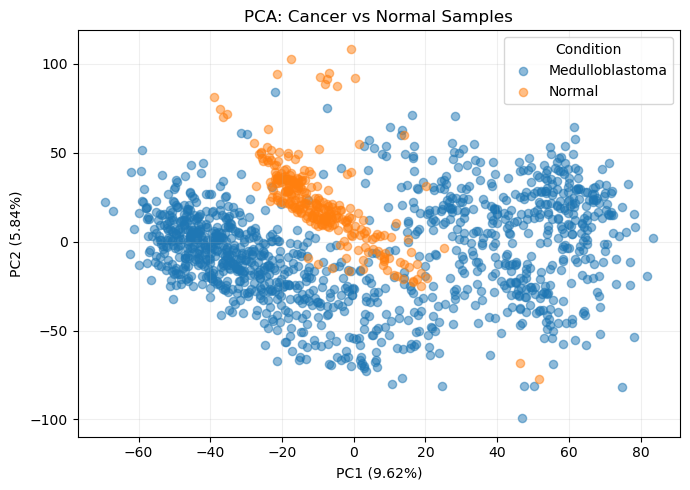

In [34]:
plt.figure(figsize=(7, 5))

for condition in pca_df["Condition"].unique():
    subset = pca_df[pca_df["Condition"] == condition]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=condition,
        alpha=0.5,
        s=35
    )
plt.xlabel( f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)" )
plt.ylabel( f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)" )
plt.title("PCA: Cancer vs Normal Samples")
plt.legend(title="Condition") 
plt.grid(alpha=0.2) 
plt.tight_layout() 
plt.show()

#### Modeling (SVM with Scikit-learn)

In [40]:
feature = pca_df.iloc[: , :958]
X = np.asarray(feature)
X[1:5]

array([[-9.15393034e+00, -4.68477367e+01,  1.14230004e+01, ...,
        -6.87595270e-01,  1.78102151e+00, -7.10001719e-01],
       [-3.29946413e+01, -3.48825555e+01,  2.18411617e+01, ...,
         1.55121265e+00,  1.60287403e+00,  2.97221535e-01],
       [ 5.02106404e+01, -8.10004333e+01,  1.19638583e+01, ...,
         9.81389798e-01, -1.07530236e+00, -7.08114045e-02],
       [-2.87574776e+01,  6.65761927e+00,  1.95144278e+00, ...,
        -3.79330101e-01,  1.99315791e+00, -6.42730387e-01]])

In [42]:
y = pca_df.loc[:, "Condition"]
y[1:5]

1    Medulloblastoma
2    Medulloblastoma
3    Medulloblastoma
4    Medulloblastoma
Name: Condition, dtype: object

In [ ]:
# Train/Test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Train set: (1156, 958) (1156,)
Test set: (289, 958) (289,)


In [48]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

SVC()

In [52]:
# Predict
yhat = clf.predict(X_test)
print(y_test[0:5])
print(yhat[0:5])

413     Medulloblastoma
316     Medulloblastoma
1034    Medulloblastoma
65      Medulloblastoma
1024    Medulloblastoma
Name: Condition, dtype: object
['Medulloblastoma' 'Medulloblastoma' 'Medulloblastoma' 'Medulloblastoma'
 'Medulloblastoma']


# Evaluation

In [53]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

In [54]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

                 precision    recall  f1-score   support

Medulloblastoma       0.98      1.00      0.99       228
         Normal       1.00      0.93      0.97        61

       accuracy                           0.99       289
      macro avg       0.99      0.97      0.98       289
   weighted avg       0.99      0.99      0.99       289

Confusion matrix, without normalization
[[228   0]
 [  4  57]]


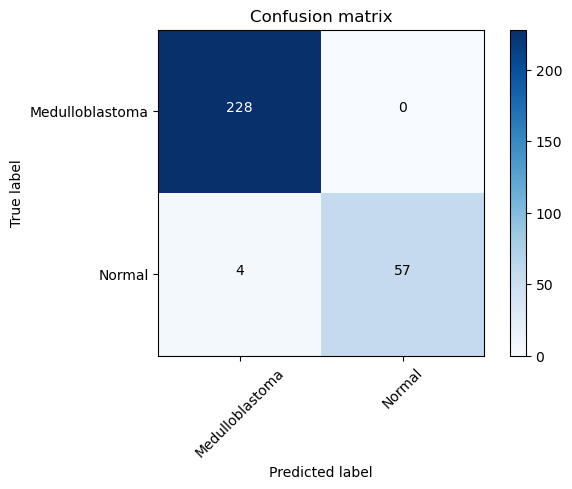

In [57]:
# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test, yhat, labels=["Medulloblastoma","Normal"])
np.set_printoptions(precision=2)

print (classification_report(y_test, yhat))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=["Medulloblastoma","Normal"],normalize= False,  title='Confusion matrix')
plt.show(1)

In [58]:
from sklearn.metrics import f1_score
f1_score(y_test, yhat, average="weighted")

0.9859847567272607

In [60]:
from sklearn.metrics import jaccard_score
jaccard_score(y_test, yhat,pos_label="Medulloblastoma")

np.float64(0.9827586206896551)